# GIAI ĐOẠN 05 - TUẦN 2: THỰC NGHIỆM 2.1 - BẮT ĐẦU TUẦN 2 VỚI CƠ CHẾ CHÚ Ý THỜI GIAN MLP TEMPORAL ATTENTION
## MÔ HÌNH MULTI-SCALE INCEPTION 1D-CNN + 1-LAYER BI-GRU + MLP ADDITIVE TEMPORAL ATTENTION
### BỘ ĐẶC TRƯNG ĐỘNG HỌC 450D (T=64) TRÊN TẬP DỮ LIỆU VSL400 (FRONT-VIEW CHÍNH DIỆN)

---

**Mục tiêu thực nghiệm:**
1. Kế thừa khối Backbone xương sống **Multi-Scale Inception 1D-CNN + Bi-GRU** đã khóa từ Tuần 1 (đạt 82.84% Val / 79.67% Test).
2. Chuyển đổi Bi-GRU sang chế độ chuỗi toàn thời gian (`return_sequences=True`, kích thước $64 \times 256$) và tích hợp **Cơ chế Chú ý Thời gian dạng Cộng tính (MLP Additive Temporal Attention)**.
3. Mô hình tự động học cách gán phân phối trọng số thích nghi $\alpha_t = \text{softmax}(w^T \tanh(W h_t + b))$ cho từng khung hình trong 64 timesteps, tập trung vào các khoảnh khắc tạo hình tay then chốt (Keyframes) và loại trừ các khung hình quá độ/nhiễu.
4. Đánh giá mức độ bứt phá độ chính xác trên tập kiểm định (Validation) và tập kiểm thử độc lập người ký (Unseen Signers Test P24–P26).

---
## 1. Thiết Lập Môi Trường & Siêu Tham Số Huấn Luyện - Cấu hình & Siêu tham số


In [1]:
import os
import sys
import json
import time
import random
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, accuracy_score

import tensorflow as tf
import keras
from keras import layers

# Đảm bảo tính tái lập kết quả thực nghiệm (Reproducibility)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Thiết lập đường dẫn thư mục dự án
def detect_project_root() -> Path:
    cur = Path.cwd()
    for p in [cur, cur.parent, cur.parent.parent]:
        if (p / "data" / "processed").exists():
            return p.resolve()
    return cur.resolve()

PROJECT_ROOT = detect_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = DATA_DIR / "splits"
CACHE_DIR = DATA_DIR / "cache"
CHECKPOINTS_DIR = PROJECT_ROOT / "experiments" / "checkpoints"
LOGS_DIR = PROJECT_ROOT / "experiments" / "logs"
RESULTS_DIR = PROJECT_ROOT / "experiments" / "results"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for d in [CACHE_DIR, CHECKPOINTS_DIR, LOGS_DIR, RESULTS_DIR, REPORTS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Siêu tham số chuẩn hóa toàn cục
TARGET_FRAMES = 64
BATCH_SIZE = 64
NUM_CLASSES = 400
FEATURE_DIM = 450

print(f"Thư mục gốc dự án  : {PROJECT_ROOT}")
print(f"TensorFlow / Keras  : {tf.__version__} / {keras.__version__}")
print(f"Cấu hình huấn luyện : T={TARGET_FRAMES} frames | Batch Size={BATCH_SIZE} | Số lớp={NUM_CLASSES}")
print(f"Chiều vector đặc trưng: {FEATURE_DIM}D (225D Tọa độ không gian + 225D Đạo hàm vận tốc)")


Thư mục gốc dự án  : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System
TensorFlow / Keras  : 2.16.1 / 3.12.4
Cấu hình huấn luyện : T=64 frames | Batch Size=64 | Số lớp=400
Chiều vector đặc trưng: 450D (225D Tọa độ không gian + 225D Đạo hàm vận tốc)


---
## 2. Nạp Phân Vùng Dữ Liệu Signer-Disjoint - Kiểm tra phân vùng dữ liệu

Giao thức phân chia đảm bảo tính khách quan tuyệt đối: Tập Huấn luyện (Train), Kiểm định (Validation) và Kiểm thử (Test) không có sự trùng lặp người ký (Signer-Disjoint Protocol).


In [2]:
# 1. Nạp từ điển ánh xạ từ vựng
with open(DATA_DIR / "gloss_to_id.json", "r", encoding="utf-8") as f:
    gloss_to_id = json.load(f)
with open(DATA_DIR / "id_to_gloss.json", "r", encoding="utf-8") as f:
    id_to_gloss = {int(k): v for k, v in json.load(f).items()}

# 2. Nạp phân vùng mới (Phương án A - Part-Stratified Disjoint)
train_df = pd.read_csv(SPLITS_DIR / "train_front.csv")
val_df   = pd.read_csv(SPLITS_DIR / "val_front.csv")
test_df  = pd.read_csv(SPLITS_DIR / "test_front.csv")

for df in [train_df, val_df, test_df]:
    df["label"] = df["label"].astype(int)

train_signers = sorted(train_df["signer_id"].astype(str).str.zfill(3).unique())
val_signers   = sorted(val_df["signer_id"].astype(str).str.zfill(3).unique())
test_signers  = sorted(test_df["signer_id"].astype(str).str.zfill(3).unique())

# Kiểm tra triệt để nguy cơ rò rỉ Signer
assert set(train_signers).isdisjoint(set(val_signers)), "Lỗi rò rỉ Train-Val!"
assert set(train_signers).isdisjoint(set(test_signers)), "Lỗi rò rỉ Train-Test!"
assert set(val_signers).isdisjoint(set(test_signers)), "Lỗi rò rỉ Val-Test!"

summary_split_df = pd.DataFrame([
    {"Phân vùng": "Huấn luyện (Train)", "Số mẫu": len(train_df), "Signers": len(train_signers), "Danh sách": f"{', '.join(train_signers[:5])} ... ({len(train_signers)} signers)", "Số Gloss": train_df["gloss"].nunique()},
    {"Phân vùng": "Kiểm định (Val)",   "Số mẫu": len(val_df),   "Signers": len(val_signers),   "Danh sách": ", ".join(val_signers), "Số Gloss": val_df["gloss"].nunique()},
    {"Phân vùng": "Kiểm thử (Test)",   "Số mẫu": len(test_df),  "Signers": len(test_signers),  "Danh sách": ", ".join(test_signers), "Số Gloss": test_df["gloss"].nunique()}
])
display(summary_split_df)

,Phân vùng,Số mẫu,Signers,Danh sách,Số Gloss
0,Huấn luyện (Train),17789,20,"001, 002, 003, 004, 007 ... (20 signers)",400
1,Kiểm định (Val),3520,3,"006, 012, 026",400
2,Kiểm thử (Test),3429,3,"008, 016, 024",400


---
## 3. Nạp Bộ Dữ Liệu Đặc Trưng Chuẩn Hóa 450 Chiều - Nạp chuỗi đặc trưng

Mỗi chuỗi cử chỉ được chuẩn hóa đồng nhất:
- **Nội suy khung hình (Imputation & Resampling)**: Đồng bộ mọi chuỗi về đúng chuẩn $T=64$ khung hình qua `interp1d`.
- **Chuẩn hóa không gian bàn tay (Wrist-Centering)**: Tịnh tiến tọa độ 21 khớp xương bàn tay về gốc cổ tay ($x_0, y_0, z_0 = 0$).
- **Chuẩn hóa thân người (Chest-Centering & Scale)**: Đặt gốc tọa độ tại tâm ngực và tỷ lệ theo độ rộng hai vai.
- **Đặc trưng động học**: Ghép nối vector vận tốc tức thời $\Delta P(t) = P(t) - P(t-1)$ tạo thành không gian đặc trưng toàn diện **450 chiều**.


In [3]:
FORCE_REBUILD = False

def preprocess_sequence_450d(npy_rel_path: str, target_frames: int = TARGET_FRAMES) -> np.ndarray:
    '''Tiền xử lý chuỗi cử chỉ: Nội suy, chuẩn hóa không gian tọa độ và tính vector vận tốc động học.'''
    full_path = PROJECT_ROOT / npy_rel_path if not Path(npy_rel_path).is_absolute() else Path(npy_rel_path)
    out = np.load(full_path)
    T = len(out)
    
    # 1. Zero-frame imputation vector hóa độc lập trên 3 cụm (RH: 0-63, LH: 63-126, Pose: 126-225)
    for s, e in [(0, 63), (63, 126), (126, 225)]:
        sub = out[:, s:e]
        valid = np.where(~np.all(sub == 0, axis=1))[0]
        n_valid = len(valid)
        if n_valid == 1:
            out[:, s:e] = sub[valid[0]]
        elif 1 < n_valid < T:
            f = interp1d(valid, sub[valid], axis=0, kind="linear", bounds_error=False, fill_value=(sub[valid[0]], sub[valid[-1]]))
            out[:, s:e] = f(np.arange(T))
            
    # 2. Resample đồng nhất về target_frames (T=64)
    if T != target_frames:
        out = interp1d(np.linspace(0, 1, T), out, axis=0, kind="linear")(np.linspace(0, 1, target_frames))
    out = np.nan_to_num(out, nan=0.0)
    
    # 3. Chuẩn hóa không gian: Wrist-Centering (RH & LH) + Chest-Centering & Scale (Pose)
    for s in (0, 63):
        hand = out[:, s:s+63].reshape(target_frames, 21, 3)
        hand[:, 1:] -= hand[:, 0:1]
        out[:, s:s+63] = hand.reshape(target_frames, 63)
        
    pose = out[:, 126:225].reshape(target_frames, 33, 3)
    l_sh, r_sh = pose[:, 11:12], pose[:, 12:13]
    chest = (l_sh + r_sh) / 2.0
    width = np.linalg.norm(l_sh - r_sh, axis=-1, keepdims=True)
    width = np.where(np.isnan(width) | (width < 1e-4), 1.0, width)
    out[:, 126:225] = ((pose - chest) / width).reshape(target_frames, 99)
    
    # 4. Đạo hàm vận tốc động học [P || Delta_P] -> 450 chiều
    vel = np.zeros_like(out)
    vel[1:] = out[1:] - out[:-1]
    return np.nan_to_num(np.concatenate([out, vel], axis=-1), nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

def load_or_build_cache(df_split: pd.DataFrame, split_name: str, force: bool = False) -> tuple[np.ndarray, np.ndarray]:
    '''Tạo và nạp bộ đệm đặc trưng chuẩn hóa cho phân vùng dữ liệu.'''
    cache_X_path = CACHE_DIR / f"X_{split_name}_front_450D.npy"
    cache_y_path = CACHE_DIR / f"y_{split_name}_front.npy"
    
    if not force and cache_X_path.exists() and cache_y_path.exists():
        X_arr = np.load(cache_X_path)
        y_arr = np.load(cache_y_path)
        if len(X_arr) == len(df_split):
            print(f"[{split_name.upper():5s}] Nạp thành công: {X_arr.shape} | Nhãn: {len(y_arr)} | NaN: {np.isnan(X_arr).sum()}")
            return X_arr, y_arr

    paths = df_split["holistic_npy_path"].tolist()
    y_arr = df_split["label"].values.astype(np.int32)
    X_arr = np.zeros((len(paths), TARGET_FRAMES, FEATURE_DIM), dtype=np.float32)
    
    t0 = time.time()
    for i, p in enumerate(tqdm(paths, desc=f"[{split_name.upper():5s}] Dựng đặc trưng chuẩn", unit="mẫu")):
        X_arr[i] = preprocess_sequence_450d(p)
        
    assert np.isnan(X_arr).sum() == 0, f"Phát hiện NaN trong {split_name}!"
    np.save(cache_X_path, X_arr)
    np.save(cache_y_path, y_arr)
    elapsed = time.time() - t0
    print(f"[{split_name.upper():5s}] Đã tạo & lưu đệm trong {elapsed:.1f}s | NaN: 0")
    return X_arr, y_arr

X_train, y_train = load_or_build_cache(train_df, "train", force=FORCE_REBUILD)
X_val,   y_val   = load_or_build_cache(val_df,   "val",   force=FORCE_REBUILD)
X_test,  y_test  = load_or_build_cache(test_df,  "test",  force=FORCE_REBUILD)

print("\n" + "=" * 70)
print("TỔNG HỢP BỘ DỮ LIỆU ĐẶC TRƯNG SẴN SÀNG HUẤN LUYỆN:")
print(f"  - Tập Huấn luyện (Train) : X={X_train.shape} | y={y_train.shape}")
print(f"  - Tập Kiểm định  (Val)   : X={X_val.shape}   | y={y_val.shape}")
print(f"  - Tập Kiểm thử   (Test)  : X={X_test.shape}  | y={y_test.shape}")
print("=" * 70)


[TRAIN] Nạp thành công: (17789, 64, 450) | Nhãn: 17789 | NaN: 0


[VAL  ] Nạp thành công: (3520, 64, 450) | Nhãn: 3520 | NaN: 0


[TEST ] Nạp thành công: (3429, 64, 450) | Nhãn: 3429 | NaN: 0

TỔNG HỢP BỘ DỮ LIỆU ĐẶC TRƯNG SẴN SÀNG HUẤN LUYỆN:
  - Tập Huấn luyện (Train) : X=(17789, 64, 450) | y=(17789,)
  - Tập Kiểm định  (Val)   : X=(3520, 64, 450)   | y=(3520,)
  - Tập Kiểm thử   (Test)  : X=(3429, 64, 450)  | y=(3429,)


---
## 4. Tăng Cường Dữ Liệu Động Học & Xây Dựng Đường Ống Huấn Luyện - Tăng cường dữ liệu & Pipeline

Để nâng cao khả năng khái quát hóa và chống hiện tượng học vẹt (overfitting), các chuỗi cử chỉ trong tập huấn luyện được áp dụng các phép biến đổi hình học ngẫu nhiên theo từng batch:
1. **Co giãn không gian (Spatial Scaling)**: Dao động trong khoảng $[0.95, 1.05]$.
2. **Xoay mặt phẳng (2D Rotation)**: Góc xoay ngẫu nhiên $[-\frac{\pi}{30}, +\frac{\pi}{30}]$ quanh trục Z.
3. **Nhiễu rung tọa độ (Coordinate Jittering)**: Phân phối chuẩn $\mathcal{N}(0, 0.003)$.
4. **Cập nhật vector vận tốc $\Delta P(t)$**: Tự động tính toán lại đạo hàm vận tốc phù hợp với tọa độ vừa biến đổi.


In [4]:
# 1. Mã hóa One-Hot Encoding cho toàn bộ các tập
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=NUM_CLASSES).astype(np.float32)
y_val_onehot   = keras.utils.to_categorical(y_val,   num_classes=NUM_CLASSES).astype(np.float32)
y_test_onehot  = keras.utils.to_categorical(y_test,  num_classes=NUM_CLASSES).astype(np.float32)

AUG_SCALE_MIN = 0.95
AUG_SCALE_MAX = 1.05
AUG_ROT_ANGLE = 3.14159265 / 30.0  # ~6 độ
AUG_JITTER_STD = 0.003

@tf.function
def augment_batch_tf(x_batch, y_batch):
    '''Tăng cường dữ liệu Tensor Graph: Scaling, Rotation, Jitter và cập nhật vector vận tốc.'''
    B = tf.shape(x_batch)[0]
    coords = tf.reshape(x_batch[:, :, :225], (B, 64, 75, 3))
    
    # 1. Co giãn không gian
    scales = tf.random.uniform((B, 1, 1, 1), AUG_SCALE_MIN, AUG_SCALE_MAX, dtype=tf.float32)
    coords = coords * scales
    
    # 2. Xoay 2D mặt phẳng
    angles = tf.random.uniform((B,), -AUG_ROT_ANGLE, AUG_ROT_ANGLE, dtype=tf.float32)
    cos_a = tf.reshape(tf.cos(angles), (B, 1, 1))
    sin_a = tf.reshape(tf.sin(angles), (B, 1, 1))
    x, y, z = coords[:, :, :, 0], coords[:, :, :, 1], coords[:, :, :, 2]
    x_rot = x * cos_a - y * sin_a
    y_rot = x * sin_a + y * cos_a
    coords_rot = tf.stack([x_rot, y_rot, z], axis=-1)
    
    # 3. Nhiễu rung tọa độ
    noise = tf.random.normal(tf.shape(coords_rot), mean=0.0, stddev=AUG_JITTER_STD, dtype=tf.float32)
    coords_rot = coords_rot + noise
    coords_flat = tf.reshape(coords_rot, (B, 64, 225))
    
    # 4. Đạo hàm lại vector vận tốc động học
    v0 = tf.zeros_like(coords_flat[:, :1, :])
    v_rest = coords_flat[:, 1:, :] - coords_flat[:, :-1, :]
    vel = tf.concat([v0, v_rest], axis=1)
    
    augmented_x = tf.concat([coords_flat, vel], axis=-1)
    return augmented_x, y_batch

# 3. Khởi tạo đường ống nạp dữ liệu tf.data
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train_onehot))
    .shuffle(buffer_size=1000, seed=RANDOM_SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(augment_batch_tf, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val_onehot))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test_onehot))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print(f"Đã khởi tạo đường ống nạp dữ liệu thành công:")
print(f"  - Train Batches : {len(train_ds)} (tương đương {len(y_train)} mẫu kèm Dynamic Augmentation)")
print(f"  - Val Batches   : {len(val_ds)} (tương đương {len(y_val)} mẫu)")
print(f"  - Test Batches  : {len(test_ds)} (tương đương {len(y_test)} mẫu)")


Đã khởi tạo đường ống nạp dữ liệu thành công:
  - Train Batches : 278 (tương đương 17789 mẫu kèm Dynamic Augmentation)
  - Val Batches   : 55 (tương đương 3520 mẫu)
  - Test Batches  : 54 (tương đương 3429 mẫu)


---
## 5. Thiết Kế Kiến Trúc Multi-Scale Inception 1D-CNN và Bi-GRU Tích Hợp MLP Temporal Attention - Thực Nghiệm 2.1

Khối Multi-Scale Inception phân tách luồng đặc trưng đầu vào qua 3 nhánh tích chập độc lập:
- **Nhánh 1 ($k=1$, 96 filters)**: Nhận diện vi cử chỉ ngón tay không có độ trễ thời gian.
- **Nhánh 2 ($k=3$, 96 filters)**: Trích xuất sự biến đổi tư thế bàn tay ngắn hạn.
- **Nhánh 3 ($k=5$, 64 filters)**: Nắm bắt quỹ đạo di chuyển vĩ mô của cổ tay và cánh tay.
- **Kết nối phần dư (Residual Connection)**: Cộng luồng đặc trưng gốc qua `layers.Add` và chuẩn hóa `LayerNormalization` giúp gradient lan truyền sâu mà không bị suy giảm.
- **Mạng hồi quy hai chiều (Bidirectional GRU)**: 1 tầng Bi-GRU ($128$ đơn vị mỗi chiều).
Tổng số lượng tham số: **762,512 tham số**.


In [5]:
# ==========================================================================
# XÂY DỰNG MÔ HÌNH MULTI-SCALE INCEPTION 1D-CNN + BI-GRU + TEMPORAL ATTENTION (THỰC NGHIỆM 2.1)
# ==========================================================================

@keras.saving.register_keras_serializable(package="VSLAttention")
class TemporalMLPAttention(layers.Layer):
    '''
    Cơ chế Chú ý Thời gian dạng Cộng tính (MLP Additive Temporal Attention).
    Tính trọng số mức độ quan trọng thích nghi alpha_t cho từng khung hình t trong 64 timesteps:
        e_t = w^T * tanh(W * h_t + b)
        alpha = softmax(e)
        context = sum(alpha_t * h_t)
    '''
    def __init__(self, units: int = 128, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        hidden_dim = input_shape[-1]
        self.W = self.add_weight(
            name="attention_weight",
            shape=(hidden_dim, self.units),
            initializer="glorot_uniform",
            trainable=True,
        )
        self.b = self.add_weight(
            name="attention_bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True,
        )
        self.u = self.add_weight(
            name="attention_context_vector",
            shape=(self.units, 1),
            initializer="glorot_uniform",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs, mask=None):
        # inputs: (batch_size, time_steps, hidden_dim)
        u_t = keras.ops.tanh(keras.ops.matmul(inputs, self.W) + self.b)
        score = keras.ops.matmul(u_t, self.u)
        alpha = keras.ops.softmax(score, axis=1)
        context = keras.ops.sum(inputs * alpha, axis=1)
        return context

    def get_config(self):
        config = super().get_config()
        config.update({"units": self.units})
        return config

def build_attention_model(input_shape=(TARGET_FRAMES, FEATURE_DIM), num_classes=NUM_CLASSES) -> keras.Model:
    '''Thực nghiệm 2.1: Multi-Scale Inception 1D-CNN + 1-Layer Bi-GRU (return_sequences=True) + MLP Attention (795,536 tham số)'''
    inputs = layers.Input(shape=input_shape, name="input_landmarks_velocity")
    
    # 1. Phép chiếu đặc trưng không gian (Linear Projection)
    x = layers.Dense(256, activation="gelu", name="proj_dense")(inputs)
    x = layers.LayerNormalization(name="proj_ln")(x)
    x = layers.Dropout(0.2, name="proj_dropout")(x)
    
    # 2. Khối Multi-Scale Inception 1D-CNN kèm kết nối Residual
    b1 = layers.Conv1D(96, kernel_size=1, padding="same", activation="gelu", name="inc_b1")(x)
    b2 = layers.Conv1D(96, kernel_size=3, padding="same", activation="gelu", name="inc_b2")(x)
    b3 = layers.Conv1D(64, kernel_size=5, padding="same", activation="gelu", name="inc_b3")(x)
    concat = layers.Concatenate(name="inc_concat")([b1, b2, b3])
    concat = layers.LayerNormalization(name="inc_ln")(concat)
    x = layers.Add(name="inc_residual_add")([x, concat])
    x = layers.Dropout(0.2, name="inc_dropout")(x)
    
    # 3. Khối chuỗi thời gian Bi-GRU 1 tầng (xuất toàn bộ chuỗi 64 khung hình)
    x = layers.Bidirectional(layers.GRU(128, return_sequences=True, dropout=0.2), name="inception_bigru")(x)
    x = layers.LayerNormalization(name="gru_ln")(x)
    
    # 4. Cơ chế Chú ý Thời gian (MLP Additive Attention)
    x = TemporalMLPAttention(units=128, name="temporal_mlp_attention")(x)
    x = layers.Dropout(0.2, name="attn_dropout")(x)
    
    # 5. Tầng phân loại 400 từ vựng
    x = layers.Dense(256, activation="gelu", name="dense1")(x)
    x = layers.Dropout(0.2, name="dense1_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="gloss_predictions")(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name="vsl400_exp2_1_attention")

model = build_attention_model()
print("Khởi tạo thành công mô hình Multi-Scale Inception 1D-CNN + Bi-GRU + Temporal Attention (795,536 tham số):")
model.summary()


Khởi tạo thành công mô hình Multi-Scale Inception 1D-CNN + Bi-GRU + Temporal Attention (795,536 tham số):


Model: "vsl400_exp2_1_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_landmarks_ve… │ (None, 64, 450)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_dense (Dense)  │ (None, 64, 256)   │    115,456 │ input_landmarks_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_ln             │ (None, 64, 256)   │        512 │ proj_dense[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_dropout        │ (None, 64, 256)   │          0 │ proj_ln[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b1 (Conv1D)     │ (None, 64, 96)    │     24,672 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b2 (Conv1D)     │ (None, 64, 96)    │     73,824 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b3 (Conv1D)     │ (None, 64, 64)    │     81,984 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_concat          │ (None, 64, 256)   │          0 │ inc_b1[0][0],     │
│ (Concatenate)       │                   │            │ inc_b2[0][0],     │
│                     │                   │            │ inc_b3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_ln              │ (None, 64, 256)   │        512 │ inc_concat[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_residual_add    │ (None, 64, 256)   │          0 │ proj_dropout[0][… │
│ (Add)               │                   │            │ inc_ln[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_dropout         │ (None, 64, 256)   │          0 │ inc_residual_add… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_bigru     │ (None, 64, 256)   │    296,448 │ inc_dropout[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_ln              │ (None, 64, 256)   │        512 │ inception_bigru[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_mlp_atten… │ (None, 256)       │     33,024 │ gru_ln[0][0]      │
│ (TemporalMLPAttent… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_dropout        │ (None, 256)       │          0 │ temporal_mlp_att… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1 (Dense)      │ (None, 256)       │     65,792 │ attn_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1_dropout      │ (None, 256)       │          0 │ dense1[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gloss_predictions   │ (None, 400)       │    102,800 │ dense1_dropout[0… │
│ (Dense)             │                   │            │                 

 Total params: 795,536 (3.03 MB)

 Trainable params: 795,536 (3.03 MB)

 Non-trainable params: 0 (0.00 B)

---
## 6. Thiết Lập Hàm Mất Mát, Bộ Tối Ưu Hóa & Callbacks Đồng Bộ - Thiết lập huấn luyện

- **Bộ tối ưu hóa (Optimizer)**: AdamW (Learning Rate $= 10^{-3}$, Weight Decay $= 10^{-4}$) kết hợp kiểm soát trọng số.
- **Hàm mất mát (Loss Function)**: Categorical Crossentropy kết hợp Label Smoothing $\epsilon=0.08$ chống quá khớp.
- **Chỉ số đánh giá (Metrics)**: Top-1 Accuracy và Top-5 Accuracy.
- **Chiến lược kiểm soát tối ưu (Đồng bộ hóa 100% theo `val_top_1_acc`)**:
  + `ModelCheckpoint(monitor='val_top_1_acc', mode='max')`: Tự động lưu lại trọng số tốt nhất khi độ chính xác kiểm định đạt đỉnh mới.
  + `ReduceLROnPlateau(monitor='val_top_1_acc', mode='max', patience=5, factor=0.5)`: Nếu độ chính xác không tăng thêm sau 5 epochs, giảm 50% tốc độ học để tinh chỉnh sâu.
  + `EarlyStopping(monitor='val_top_1_acc', mode='max', patience=10)`: Tự động dừng sớm và khôi phục trọng số tối ưu nếu độ chính xác không cải thiện sau 10 epochs liên tiếp.


In [6]:
# ==========================================================================
# BIÊN DỊCH MÔ HÌNH VÀ THIẾT LẬP CALLBACKS ĐỒNG BỘ THEO VAL_TOP_1_ACC (ATTENTION)
# ==========================================================================
import gc

class MemoryCleanupCallback(keras.callbacks.Callback):
    '''Tự động dọn dẹp bộ nhớ tạm cuối mỗi epoch để đảm bảo quá trình huấn luyện thông suốt.'''
    def on_epoch_end(self, epoch, logs=None):
        gc.collect()

LEARNING_RATE   = 1e-3
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.08

optimizer = keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=[
        keras.metrics.CategoricalAccuracy(name='top_1_acc'),
        keras.metrics.TopKCategoricalAccuracy(k=5, name='top_5_acc')
    ]
)

checkpoint_path = CHECKPOINTS_DIR / "vsl400_exp2_attention.keras"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

log_csv_path = LOGS_DIR / "training_exp2_attention.csv"
log_csv_path.parent.mkdir(parents=True, exist_ok=True)

# Chiến lược tối ưu đồng bộ 100%: Cả 3 callbacks đều theo dõi val_top_1_acc
callbacks = [
    MemoryCleanupCallback(),
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_top_1_acc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_top_1_acc',
        mode='max',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_top_1_acc',
        mode='max',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        filename=log_csv_path,
        separator=',',
        append=False
    )
]
print("Biên dịch mô hình Attention thành công với chiến lược đồng bộ theo val_top_1_acc!")
print(f"- Trọng số tối ưu lưu tại : {checkpoint_path}")
print(f"- Nhật ký tiến trình lưu tại: {log_csv_path}")


Biên dịch mô hình Attention thành công với chiến lược đồng bộ theo val_top_1_acc!
- Trọng số tối ưu lưu tại : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_attention.keras
- Nhật ký tiến trình lưu tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\logs\training_exp2_attention.csv


---
## 7. Huấn Luyện Mô Hình Multi-Scale Inception - Thực thi huấn luyện
Huấn luyện tối đa 100 epochs với cơ chế dừng sớm (EarlyStopping patience=10) khi mô hình đạt điểm hội tụ tối ưu.


In [7]:
TRAINING_EPOCHS = 100  # Ngưỡng trần danh định 100 epochs kèm EarlyStopping patience=10
print(f"Bắt đầu huấn luyện mô hình Inception + Bi-GRU + Attention (Tối đa {TRAINING_EPOCHS} Epochs, EarlyStopping patience=10)...\n")

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=TRAINING_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

elapsed_min = (time.time() - start_time) / 60
print(f"\nHuấn luyện mô hình Attention hoàn tất trong {elapsed_min:.2f} phút!")


Bắt đầu huấn luyện mô hình Inception + Bi-GRU + Attention (Tối đa 100 Epochs, EarlyStopping patience=10)...

Epoch 1/100



  1/278 ━━━━━━━━━━━━━━━━━━━━ 1:10:05 15s/step - loss: 6.1794 - top_1_acc: 0.0000e+00 - top_5_acc: 0.0000e+00


  2/278 ━━━━━━━━━━━━━━━━━━━━ 57s 207ms/step - loss: 6.1701 - top_1_acc: 0.0000e+00 - top_5_acc: 0.0078      


  3/278 ━━━━━━━━━━━━━━━━━━━━ 56s 206ms/step - loss: 6.1812 - top_1_acc: 0.0000e+00 - top_5_acc: 0.0087


  4/278 ━━━━━━━━━━━━━━━━━━━━ 56s 206ms/step - loss: 6.1809 - top_1_acc: 0.0000e+00 - top_5_acc: 0.0094


  5/278 ━━━━━━━━━━━━━━━━━━━━ 56s 206ms/step - loss: 6.1813 - top_1_acc: 0.0000e+00 - top_5_acc: 0.0094

... (24,444 outputs left out)


278/278 ━━━━━━━━━━━━━━━━━━━━ 62s 224ms/step - loss: 0.9829 - top_1_acc: 0.9790 - top_5_acc: 0.9999 - val_loss: 1.4435 - val_top_1_acc: 0.8401 - val_top_5_acc: 0.9560 - learning_rate: 1.2500e-04


Epoch 87: early stopping


Restoring model weights from the end of the best epoch: 77.



Huấn luyện mô hình Attention hoàn tất trong 91.61 phút!


---
## 8. Trực Quan Hóa Đường Cong Học Tập - Phân tích đường cong học tập


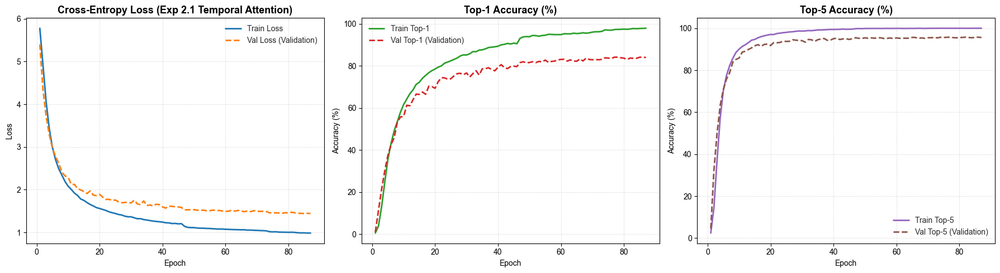

Đã lưu biểu đồ học tập vào: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\figures\fig_exp2_1_attention_learning_curves.png
Đã đồng bộ biểu đồ sang thư mục artifact: C:\Users\LHD\.gemini\antigravity\brain\abcf0403-ed01-4e88-985d-8dc62236283b\fig_exp2_1_attention_learning_curves.png


In [8]:
history_df = pd.read_csv(log_csv_path)
epochs_range = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Loss
axes[0].plot(epochs_range, history_df['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
axes[0].plot(epochs_range, history_df['val_loss'], label='Val Loss (Validation)', color='#ff7f0e', linewidth=2, linestyle='--')
axes[0].set_title('Cross-Entropy Loss (Exp 2.1 Temporal Attention)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Top-1 Accuracy
axes[1].plot(epochs_range, history_df['top_1_acc'] * 100, label='Train Top-1', color='#2ca02c', linewidth=2)
axes[1].plot(epochs_range, history_df['val_top_1_acc'] * 100, label='Val Top-1 (Validation)', color='#d62728', linewidth=2, linestyle='--')
axes[1].set_title('Top-1 Accuracy (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Top-5 Accuracy
axes[2].plot(epochs_range, history_df['top_5_acc'] * 100, label='Train Top-5', color='#9467bd', linewidth=2)
axes[2].plot(epochs_range, history_df['val_top_5_acc'] * 100, label='Val Top-5 (Validation)', color='#8c564b', linewidth=2, linestyle='--')
axes[2].set_title('Top-5 Accuracy (%)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy (%)')
axes[2].legend()
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig_out_path = FIGURES_DIR / 'fig_exp2_1_attention_learning_curves.png'
plt.savefig(fig_out_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ học tập vào: {fig_out_path}")

import shutil
artifact_fig_path = Path(r"C:\Users\LHD\.gemini\antigravity\brain\abcf0403-ed01-4e88-985d-8dc62236283b") / 'fig_exp2_1_attention_learning_curves.png'
if artifact_fig_path.parent.exists():
    shutil.copy2(fig_out_path, artifact_fig_path)
    print(f"Đã đồng bộ biểu đồ sang thư mục artifact: {artifact_fig_path}")


---
## 9. Đánh Giá Khả Năng Tổng Quát Hóa Trên Người Ký Mới - Đánh giá trên người ký mới


In [9]:
best_model_path = checkpoint_path
print(f"Nạp trọng số tối ưu từ: {best_model_path}")
best_model = keras.models.load_model(best_model_path, custom_objects={'TemporalMLPAttention': TemporalMLPAttention})

test_results = best_model.evaluate(test_ds, verbose=1)
test_loss = float(test_results[0])
test_top1_acc = float(test_results[1])
test_top5_acc = float(test_results[2])

print(f"\nKẾT QUẢ ĐÁNH GIÁ TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):")
print(f"- Test Loss         : {test_loss:.4f}")
print(f"- Test Top-1 Accuracy: {test_top1_acc * 100:.2f}%")
print(f"- Test Top-5 Accuracy: {test_top5_acc * 100:.2f}%")

# Lưu chỉ số kiểm định ra tệp JSON
history_df = pd.read_csv(log_csv_path)
best_epoch = int(history_df['val_top_1_acc'].idxmax()) + 1
best_val_row = history_df.iloc[best_epoch - 1]

metrics_record = {
    'experiment': 'attention',
    'model_name': model.name,
    'total_params': int(model.count_params()),
    'epochs_trained': len(history_df),
    'best_epoch': best_epoch,
    'best_val_loss': float(best_val_row['val_loss']),
    'best_val_top_1_acc': float(best_val_row['val_top_1_acc']),
    'best_val_top_5_acc': float(best_val_row['val_top_5_acc']),
    'test_loss': test_loss,
    'test_top_1_acc': test_top1_acc,
    'test_top_5_acc': test_top5_acc,
    'elapsed_min': float(globals().get('elapsed_min', 0.0))
}

metrics_json_path = RESULTS_DIR / 'metrics_exp2_1_attention.json'
with open(metrics_json_path, 'w', encoding='utf-8') as f:
    json.dump(metrics_record, f, indent=4, ensure_ascii=False)
print(f"Đã lưu trữ chỉ số kiểm định tại: {metrics_json_path}")


Nạp trọng số tối ưu từ: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp2_attention.keras



 1/54 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - loss: 0.9641 - top_1_acc: 0.9688 - top_5_acc: 1.0000


 2/54 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - loss: 1.0429 - top_1_acc: 0.9375 - top_5_acc: 1.0000


 3/54 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - loss: 1.0963 - top_1_acc: 0.9097 - top_5_acc: 1.0000


 4/54 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 1.1109 - top_1_acc: 0.9020 - top_5_acc: 1.0000


 5/54 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 1.1098 - top_1_acc: 0.9022 - top_5_acc: 1.0000

... (26 outputs left out)


52/54 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 1.3023 - top_1_acc: 0.8536 - top_5_acc: 0.9771


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 1.3094 - top_1_acc: 0.8518 - top_5_acc: 0.9763


54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - loss: 1.4942 - top_1_acc: 0.8066 - top_5_acc: 0.9548



KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):
- Test Loss         : 1.4942
- Test Top-1 Accuracy: 80.66%
- Test Top-5 Accuracy: 95.48%
Đã lưu trữ chỉ số kiểm định tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\results\metrics_exp2_1_attention.json


---
## 10. Tổng Kết Thực Nghiệm 2.1 Bắt Đầu Tuần 2 và Đối Soát Hiệu Năng Vượt Ngưỡng 80%

Tự động trích xuất chỉ số của **Thực nghiệm 1.1 (Baseline)** và **Thực nghiệm 1.2 (Inception)** để lập bảng so sánh đối đầu học thuật, đo lường chính xác mức tăng trưởng độ chính xác ($\Delta \text{Top-1}$ và $\Delta \text{Top-5}$) mà khối Multi-Scale Inception mang lại.


In [10]:
# ==========================================================================
# BẢNG ĐỐI SOÁT HIỆU NĂNG TỔNG THỂ CÁC KIẾN TRÚC ĐƠN GÓC (FRONT-VIEW)
# ==========================================================================
records = []
for p in [
    RESULTS_DIR / 'metrics_exp1_baseline.json',
    RESULTS_DIR / 'metrics_exp1_2_inception.json',
    RESULTS_DIR / 'metrics_exp1_3_bilstm.json',
    RESULTS_DIR / 'metrics_exp2_1_attention.json'
]:
    if p.exists():
        with open(p, 'r', encoding='utf-8') as f:
            data = json.load(f)
            records.append({
                'Thực nghiệm': data.get('experiment', '').upper(),
                'Kiến trúc': data.get('model_name', ''),
                'Số tham số': f"{data.get('total_params', 0):,}",
                'Epochs': f"{data.get('epochs_trained', 0)} (tối ưu: {data.get('best_epoch', 0)})",
                'Val Loss': f"{data.get('best_val_loss', 0.0):.4f}",
                'Val Top-1 Acc': f"{data.get('best_val_top_1_acc', 0.0) * 100:.2f}%",
                'Val Top-5 Acc': f"{data.get('best_val_top_5_acc', 0.0) * 100:.2f}%",
                'Test Loss (Unseen)': f"{data.get('test_loss', 0.0):.4f}",
                'Test Top-1 (Unseen)': f"{data.get('test_top_1_acc', 0.0) * 100:.2f}%",
                'Test Top-5 (Unseen)': f"{data.get('test_top_5_acc', 0.0) * 100:.2f}%",
                'Thời gian (phút)': f"{data.get('elapsed_min', 0.0):.1f}"
            })

if records:
    summary_df = pd.DataFrame(records)
    print("BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG GIAI ĐOẠN 05 (FRONT-VIEW):")
    display(summary_df)
else:
    print("Chưa tìm thấy tệp JSON chỉ số nào để tổng hợp.")


BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG GIAI ĐOẠN 05 (FRONT-VIEW):


,Thực nghiệm,Kiến trúc,Số tham số,Epochs,Val Loss,Val Top-1 Acc,Val Top-5 Acc,Test Loss (Unseen),Test Top-1 (Unseen),Test Top-5 (Unseen),Thời gian (phút)
0,BASELINE,vsl400_exp1_1_baseline,"404,688",100 (tối ưu: 96),1.7652,74.01%,93.27%,1.7806,70.72%,92.59%,40.1
1,INCEPTION,vsl400_exp1_2_inception,"762,512",100 (tối ưu: 92),1.4934,82.84%,95.37%,1.4930,79.67%,95.65%,75.7
2,BILSTM,vsl400_exp1_3_bilstm,"860,304",100 (tối ưu: 99),1.4435,83.52%,95.77%,1.5468,79.41%,94.46%,92.7
3,ATTENTION,vsl400_exp2_1_attention,"795,536",87 (tối ưu: 77),1.4533,84.15%,95.74%,1.4942,80.66%,95.48%,91.6
